In [1]:
# Danila Valko
# April 2026

### Setup

In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from numbers import Number
from scipy import stats
from itertools import pairwise
from scipy.stats import mannwhitneyu, friedmanchisquare, wilcoxon
import warnings

warnings.filterwarnings("ignore")

In [2]:
base_dir = './'
data_dir = os.path.join(base_dir, 'data')
figures_dir = os.path.join(base_dir, 'figures')
os.makedirs(figures_dir, exist_ok=True)  

cleaned_data = pd.read_csv(os.path.join(data_dir, 'cleaned_data.csv'))

In [3]:
def q(s, data):
    ret = []
    if isinstance(s, list):
        for i in s:
            j = q(i, data)
            if pd.notna(j):
                ret += [j]
        return ret
    for i in data.columns:
        if i.startswith(s):
            return i
    return s
        
def draw_pie(data, nrows=1, ncols=1, titles=None, labeldistance=1.2, file_name=None, width=4, height=4.5, fixed_layout=False):
    plt.close()
    fig = plt.figure(figsize=(width*ncols, height*nrows))
    pie_side = 2.6  # inches; fixed square axes => identical pie size when fixed_layout=True
    for i, c in enumerate(data.columns):
        if fixed_layout:
            ax = fig.add_axes([(1 - pie_side/width)/2, (1 - pie_side/height)/2, pie_side/width, pie_side/height])
        else:
            ax = fig.add_subplot(nrows, ncols, i+1)
        d = data[c].value_counts() / len(data) * 100
        d.sort_index(inplace=True)
        d.index = [f"{v:.1f}%\n{i}" for i, v in d.items()]
        wedges, texts = ax.pie(
            d.values,
            labels=d.index,
            #startangle=90,
            labeldistance=labeldistance,
            textprops={'fontsize': 11.5},
            colors=sns.color_palette('Set2'),
        )
        if titles:
            ax.set_title(f"{titles[i]}\n",#\n($n=${len(data)})", 
                         fontdict={'fontsize': 12,
                                   'verticalalignment': 'bottom',
                                   'horizontalalignment': 'center'})
    if not fixed_layout:
        fig.tight_layout(pad=0.5, h_pad=0, w_pad=0.1)
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200,
                    bbox_inches=None if fixed_layout else 'tight', format='pdf')
    return ax
        

def radar_chart_ci(
    questions,
    columns,
    data,
    labels={},
    title=None,
    file_name=None,
    left=3,
    ci=0.95,
    ci_method="sem",  # "sem", "std", or "quantile"
    loc="upper center",
    linestyle='--',
    verbose=True,
    figsize=(5.5, 5.5),
    add_stars=False
):
    plt.close()
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(polar=True)
    categories = [labels.get(q, q) for q in questions[:-1]]
    N = len(categories)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles[:-1], categories, size=11)
    ax.set_rlabel_position(0)
    ax.set_yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=11)
    ax.set_ylim(0, 5)
    df = data[columns].dropna()
    group_col = columns[-1]
    value_cols = columns[:-1][:N]
    z = stats.norm.ppf(1 - (1 - ci) / 2)
    differences = {}
    for idx, group in enumerate(df[group_col].drop_duplicates().sort_values()):
        differences.setdefault(group_col, {})
        d = df[df[group_col] == group][value_cols]
        differences[group_col][group] = d
        m = d.mean()
        if verbose:
            print(f"Group: {group_col}:{group} = {m}")
        std = d.std()
        n = d.count()
        if ci_method == "std":
            lower = m - std
            upper = m + std
        elif ci_method == "quantile":
            lower = d.quantile((1 - ci) / 2)
            upper = d.quantile(1 - (1 - ci) / 2)
        else:  # SEM (default)
            sem = std / np.sqrt(n)
            lower = m - z * sem
            upper = m + z * sem
        # close polygons
        mean_vals = m.tolist() + [m.iloc[0]]
        lower_vals = lower.tolist() + [lower.iloc[0]]
        upper_vals = upper.tolist() + [upper.iloc[0]]
        if isinstance(linestyle, str):
            ls = linestyle
        else:
            if group in linestyle:
                ls = linestyle[group]
            else:                
                ls = '--'
        line, = ax.plot(angles, mean_vals, 'o-', linewidth=2, label=group, linestyle=ls,
                        color=sns.color_palette('Set2')[idx])
        ax.fill_between(
            angles,
            lower_vals,
            upper_vals,
            alpha=0.2,
            color=line.get_color()
        )
    for k, v in differences.items():
        for (i0, d0), (i1, d1) in list(pairwise(v.items())):
            for col in d0.columns:
                if verbose:
                    print(f"\nComparing groups by {col}:")
                    print(f"avg. {i0}: {d0[col].mean():.2f}")
                    print(f"avg. {i1}: {d1[col].mean():.2f}")
                    u, p = mannwhitneyu(d0[col], d1[col])
                    print(f"Mann-Whitney U test: U={u:.1f}, p={p:.4f}")
    if loc is not None:
        leg = ax.legend(
            loc=loc,
            bbox_to_anchor=(0.5, -0.10),
            ncol=N,
            fontsize=11,
            frameon=False
        )
        if questions[-1] in labels:
            lb = labels[questions[-1]]
            p = leg.get_window_extent()
            ax.annotate(
                lb,
                (np.min([p.p0[0] - left * len(lb) / 2, p.p1[0]]),
                np.max([p.p0[1], p.p1[1]])),
                xycoords="figure pixels",
                zorder=9,
                size=12
            )
    if title:
        ax.set_title(
            f"{title}\n",
            fontdict={
                "fontsize": 11,
                "verticalalignment": "top",
                "horizontalalignment": "center",
            },
        )
    fig.tight_layout()
    if file_name:
        fig.savefig(os.path.join(figures_dir, f"{file_name}.pdf"),
                    dpi=1200, bbox_inches="tight")
    return ax

def radar_chart(questions, columns, data, 
    labels={}, 
    title=None, 
    file_name=None, 
    left=3,
    loc="upper center",
    linestyle='--',
    verbose=True,
    no_fill=True, figsize=(5.5, 5.5)):
    plt.close()
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(polar=True)  
    categories = [i if i not in labels else labels[i] for i in questions[:-1]]
    N = len(categories)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles[:-1], categories, size=12)
    ax.tick_params(axis='x', pad=30)
    ax.set_rlabel_position(0)
    ax.set_yticks([1,2,3,4,5], ["1","2","3","4","5"], color="grey", size=11)
    ax.set_ylim(0,5)
    df = data[columns].dropna()
    for idx, i in enumerate(df[columns[-1]].drop_duplicates().sort_values()):
        d = df[df[columns[-1]] == i].dropna()
        d = d[d.columns[:len(categories)]].mean()
        if verbose:
            print(i)
            print(d)
        d = list(d.values) + [d.values[0]]
        if isinstance(linestyle, str):
            ls = linestyle
        else:
            if i in linestyle:
                ls = linestyle[i]
            else:                
                ls = '--'
        ax.plot(angles, d, 'o-', linewidth=2, label=i, linestyle=ls,
                color=sns.color_palette('Set2')[idx])
        if not no_fill:
            ax.fill(angles, d, alpha=0.2)
    if loc is not None:
        leg = ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10),
            fancybox=False, shadow=False, ncol=N if N <=4 else round(N/2), fontsize=11, frameon=False)
        p = leg.get_window_extent()
        if questions[-1] in labels:
            lb = labels[questions[-1]] 
            ax.annotate(lb, (np.min([p.p0[0] - left * len(lb) / 2, p.p1[0]]), 
                            np.max([p.p0[1], p.p1[1]])), xycoords='figure pixels', zorder=9, size=12)
        #ax.text(0.55, 6, f"$n=${len(df)}", fontsize=11)
    if title:
        ax.set_title(f"{title}\n",#($n=${len(data)})\n", 
                         fontdict={'fontsize': 11,
                                   'verticalalignment': 'top',
                                   'horizontalalignment': 'center'})
    fig.tight_layout()
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
    return ax

def draw_hbar(questions, columns, data, file_name=None,
       labels={}, xlabel=None, ylabel=None, figsize=(9, 4.5), annot=None):
    df = data.copy()
    plt.close()
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot()
    sns.barplot(df, ax=ax, palette="Set2", orient='h', ci=95)
    ax.set_xlim(0.9, 5.3)
    ax.set_xticks([1,2,3,4,5], ["1","2","3","4","5"], size=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    q = [labels[i] if i in labels else i for i in questions]
    ax.set_yticklabels(q, size=12)
    if annot:
        for i, (bar, value) in enumerate(zip(ax.patches, annot)):
            ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2 - 0.2, value, ha='left', va='center', fontsize=11)
    fig.tight_layout()
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
    return ax

def get_stars(p, p001="***", p01="**", p05="*", p10="⁺", p_=""):
    if not isinstance(p, Number):
        return p
    if p < 0.001:
        return p001
    if p < 0.010:
        return p01
    if p < 0.050:
        return p05
    if p < 0.100:
        return p10
    return p_

### Bar-chart and distribution helpers
Companions to the pie / radar / bar figures: categorical items get bar charts of response shares; Likert items get grey mean bars with 95% CI whiskers and every individual response as a jittered dot.

In [4]:
def draw_cat_bar(data, titles=None, file_name=None, width=4.5, height=3, sort=True, xlabel=None, don=True):
    """Companion to draw_pie: horizontal bars with share of responses (and counts)."""
    plt.close()
    ncols = len(data.columns)
    fig, axes = plt.subplots(1, ncols, figsize=(width*ncols, height), squeeze=False)
    for i, c in enumerate(data.columns):
        ax = axes[0, i]
        counts = data[c].value_counts()
        counts = counts.sort_index() if sort else counts
        pct = counts / len(data) * 100
        labels = [str(l).replace('\n', ' ').strip() for l in counts.index]
        colors = sns.color_palette('Set2')[:len(counts)]
        ax.barh(labels, pct.values, color=colors)
        ax.invert_yaxis()
        for y, (p, n) in enumerate(zip(pct.values, counts.values)):
            ax.text(p + pct.max() * 0.02, y, f"{p:.1f}% ($n={n}$)" if don else f"{p:.1f}% (${n}$)", va='center', fontsize=10.5)
        ax.set_xlim(0, pct.max() * 1.45)
        ax.set_xlabel(xlabel or 'Share of respondents, %', size=11)
        ax.tick_params(axis='y', labelsize=11)
        sns.despine(ax=ax)
        if titles:
            ax.set_title(titles[i], size=12)
    fig.tight_layout()
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
    return axes


def draw_likert_dist(data, columns, labels=None, group=None, annot=None, file_name=None,
                     figsize=(9, 4.5), xlabel=None, levels=(1, 2, 3, 4, 5), seed=0):
    """Light-grey bars with mean and 95% CI whiskers; on top every individual response as a
    jittered dot (coloured per item, or per group if `group` is given)."""
    plt.close()
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(figsize=figsize)
    groups = [None] if group is None else sorted(data[group].dropna().unique())
    n_g = len(groups)
    h = 0.8 / n_g
    palette = sns.color_palette('Set2')
    for gi, g in enumerate(groups):
        d = data if g is None else data[data[group] == g]
        for i, c in enumerate(columns):
            color = palette[i] if g is None else palette[gi]
            v = d[c].dropna().astype(float)
            y = i + (gi - (n_g - 1) / 2) * h
            m = v.mean()
            ci = 1.96 * v.std() / np.sqrt(len(v))
            ax.barh(y, m, height=h * 0.85, color='#e6e6e6', zorder=1)
            ax.scatter(v + rng.uniform(-0.12, 0.12, len(v)), y + rng.uniform(-0.3, 0.3, len(v)) * h,
                       s=28, color=color, edgecolor='black', linewidth=0.4, alpha=0.8, zorder=2)
            ax.errorbar(m, y, xerr=ci, color='black', capsize=3, lw=1.3, zorder=3)
    ax.set_yticks(range(len(columns)))
    ax.set_yticklabels([(labels or {}).get(c, c) for c in columns], size=12)
    ax.set_ylim(len(columns) - 0.5, -0.5)
    ax.set_xlim(0.4, 5.4 if annot is None else 6.4)
    ax.set_xticks(list(levels), [str(l) for l in levels], size=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', color='lightgrey', lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    if annot:
        for i, a in enumerate(annot):
            ax.text(5.55, i, a, ha='left', va='center', fontsize=11)
    sns.despine(ax=ax)
    if group is not None:
        gh = [plt.Line2D([], [], marker='o', ls='', color=palette[i], markeredgecolor='black',
                         markeredgewidth=0.4) for i in range(n_g)]
        ax.legend(gh, groups, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=n_g,
                  frameon=False, fontsize=11)
    fig.tight_layout()
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
    return ax

### Figures

27


['How many years of experience do you have in research or development?']

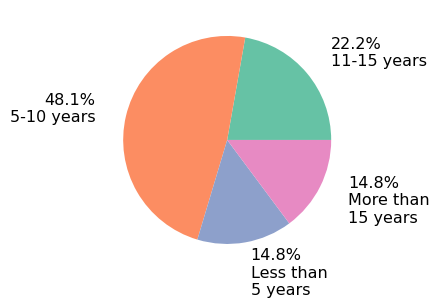

In [5]:
qs = ['How many years of experience do you have in research or development?',   ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    '5–10': '5-10 years',
    '11–15': '11-15 years',
    'Less than 5': 'Less than\n5 years',
    'More than 15': 'More than\n15 years',
    np.nan: 'No data',
    None: 'No data',
})
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig01a', 
         labeldistance=1.3, 
         width=5.8, height=4.4, fixed_layout=True)
qq

array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

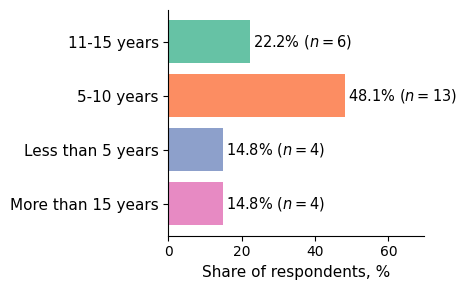

In [6]:
draw_cat_bar(df, file_name='fig01a_bar')

27


['What is your level of education or expertise?']

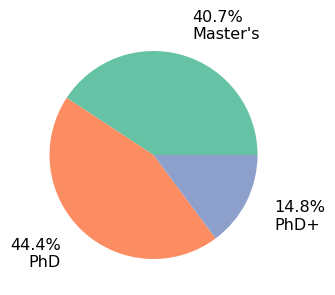

In [8]:
qs = ['What is your level of education or expertise?',   ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'PhD+ (Prof., Group Lead etc.)': 'PhD+',
    np.nan: 'No data',
    None: 'No data',
})
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig01b', 
         labeldistance=1.3, width=5.8, height=4.4, fixed_layout=True)
qq

array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

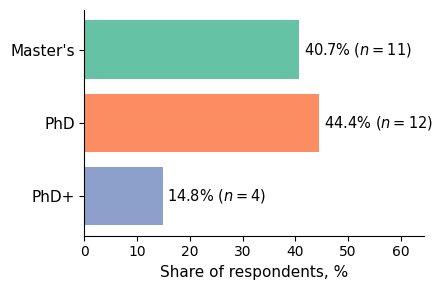

In [9]:
draw_cat_bar(df, file_name='fig01b_bar')

27


['Do you have experience collecting data or preparing datasets for research purposes?']

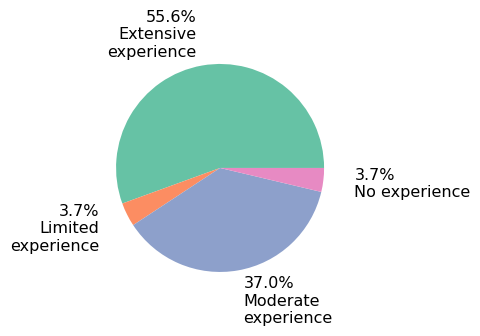

In [10]:
qs = ['Do you have experience collecting data or preparing datasets for research purposes?',   ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'No experience': 'No experience',
    'Limited experience (did it once)': 'Limited\nexperience',
    'Moderate experience (did it more than once)': 'Moderate\nexperience',
    'Moderate experience': 'Moderate\nexperience',
    'Extensive experience': 'Extensive\nexperience',
    np.nan: 'No data',
    None: 'No data',
})
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig01c',
         labeldistance=1.3,
         width=5.8, height=4.4, fixed_layout=True)                          
qq

array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

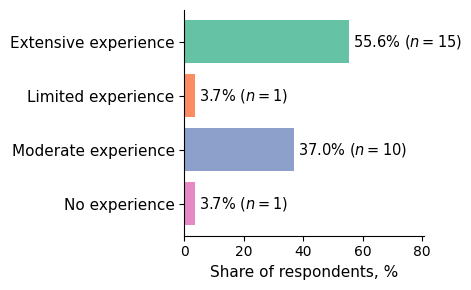

In [11]:
draw_cat_bar(df, file_name='fig01c_bar')

27


['Do you have experience developing software or using programming languages for research?']

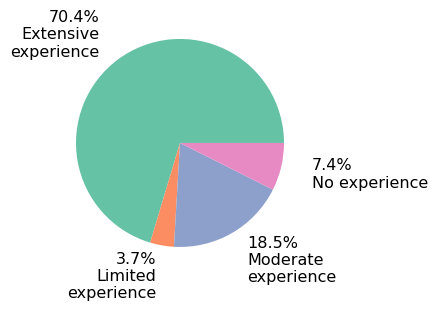

In [12]:
qs = ['Do you have experience developing software or using programming languages for research?',   ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'No experience': 'No experience',
    'Limited experience (did it once)': 'Limited\nexperience',
    'Moderate experience (did it more than once)': 'Moderate\nexperience',
    'Moderate experience': 'Moderate\nexperience',
    'Extensive experience': 'Extensive\nexperience',
    np.nan: 'No data',
    None: 'No data',
})
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig01d',
         labeldistance=1.3,
         width=5.8, height=4.4, fixed_layout=True)                          
qq

array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

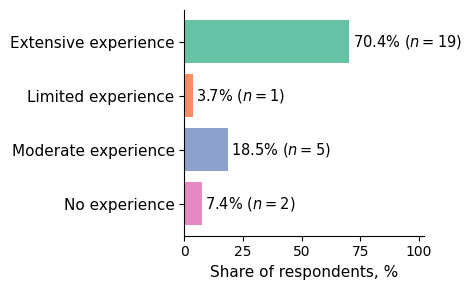

In [13]:
draw_cat_bar(df, file_name='fig01d_bar')

27


<Axes: >

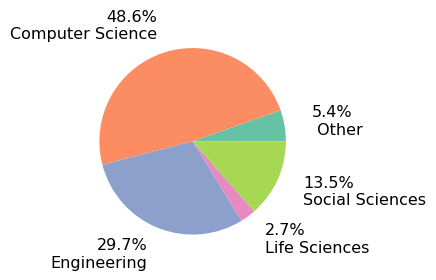

In [14]:
qs = ['What is your primary field of research or development? [Computer Science related]', 
      'What is your primary field of research or development? [Engineering related]', 
      'What is your primary field of research or development? [Social Sciences related]', 
      'What is your primary field of research or development? [Life Sciences related]', 
      'What is your primary field of research or development? [Other]']
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)

df = df[qq].replace({
    'Yes': 1,
    'No': np.nan,
})
print(len(df))
df[qq[0]] = df[qq[0]].map({
    1: 'Computer Science',
    0: np.nan,
})
df[qq[1]] = df[qq[1]].map({
    1: 'Engineering',
    0: np.nan,
})
df[qq[2]] = df[qq[2]].map({
    1: 'Social Sciences',
    0: np.nan,
})
df[qq[3]] = df[qq[3]].map({
    1: 'Life Sciences',
    0: np.nan,
})
df[qq[4]] = df[qq[4]].apply(lambda x: 'Other' if not pd.isna(x) else np.nan)

df = pd.DataFrame(pd.concat([df[i] for i in df.columns], axis=0).dropna()).replace({
    'Other': ' Other',
    np.nan: 'No data',
    None: 'No data',
})

draw_pie(df, nrows=1, ncols=1, file_name='fig02', width=4, height=4,
         labeldistance=1.3, )


array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

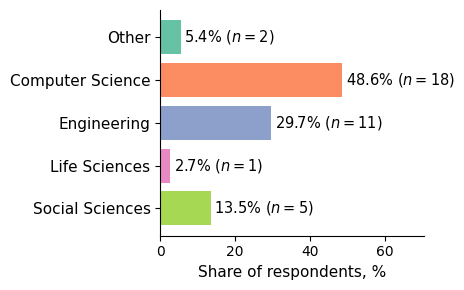

In [15]:
draw_cat_bar(df, file_name='fig02_bar')

27
Group: Category:Average value = How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)    3.962963
How familiar are you with the sustainability concept (e.g., Sustainable Development Goals) in general? 1 (Not familiar) – 5 (Very familiar)                        3.592593
How familiar are you with green software practices in general? 1 (Not familiar) – 5 (Very familiar)                                                                2.666667
dtype: float64


<PolarAxes: >

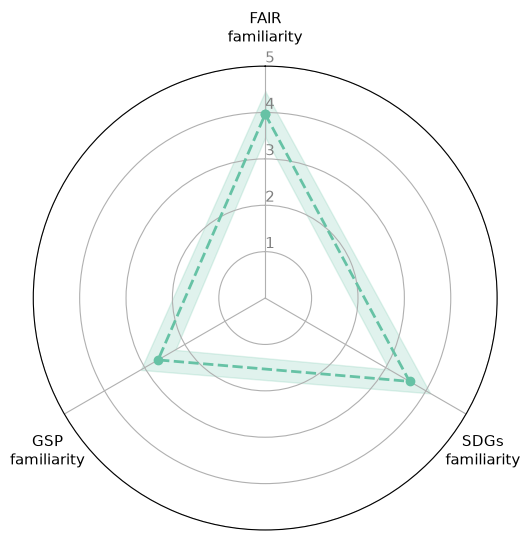

In [16]:
qs = ['How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)', 
      'How familiar are you with the sustainability concept (e.g., Sustainable Development Goals) in general? 1 (Not familiar) – 5 (Very familiar)',
      'How familiar are you with green software practices in general? 1 (Not familiar) – 5 (Very familiar)', ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna()
print(len(df))
df['Category'] = 'Average value'
radar_chart_ci(qs+['Category'], qq+['Category'], df, labels={
    qs[0]: 'FAIR\nfamiliarity\n\n',
    qs[1]: '\n\n\nSDGs\nfamiliarity',
    qs[2]: '\n\n\nGSP\nfamiliarity',
}, 
file_name='fig03', left=1, ci=0.95, ci_method="sem", 
loc=None,
linestyle='--')

<Axes: xlabel='Rating (1-5)'>

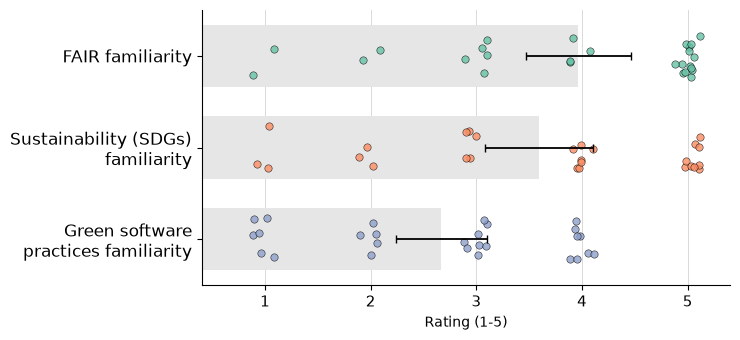

In [17]:
draw_likert_dist(df, qq, labels=dict(zip(qq, ['FAIR familiarity', 'Sustainability (SDGs)\nfamiliarity', 'Green software\npractices familiarity'])),
                  file_name='fig03_bar', figsize=(7.5, 3.5), xlabel='Rating (1-5)')

27


['How often do you participate in editorial boards, research or conference committees, or grant review activities that assess paper submissions or funding applications?']

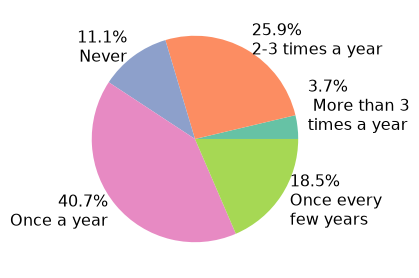

In [18]:
qs = ['How often do you participate in editorial boards, research or conference committees, or grant review activities that assess paper submissions or funding applications?',   ]
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'Once every few years': 'Once every\nfew years',
    '2–3 times a year': '2-3 times a year',
    'More than 3 times a year': ' More than 3\ntimes a year\n\n',
    np.nan: 'No data',
    None: 'No data',
})
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig04', width=4, height=4,
         labeldistance=1.1, )

qq

array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

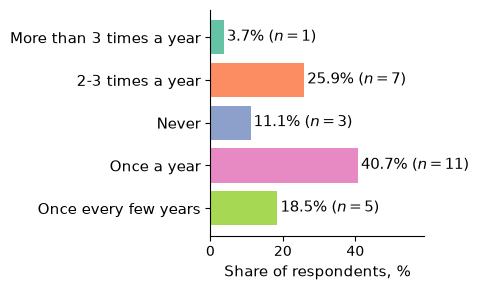

In [19]:
draw_cat_bar(df, file_name='fig04_bar')

How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)    3.962963
How important is it to follow FAIR principles? 1 (Not important) – 5 (Extremely important)                                                                         4.400000
To what extent do you apply the FAIR principles in your research or software development work? 1 (Never apply) – 5 (Always apply)                                  3.814815
dtype: float64
27 13
Group: Category:Other participants = How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)    3.8
How important is it to follow FAIR principles? 1 (Not important) – 5 (Extremely important)                                                                         3.7
To what extent do you apply the FAIR principles in your research or software development wor

'*'

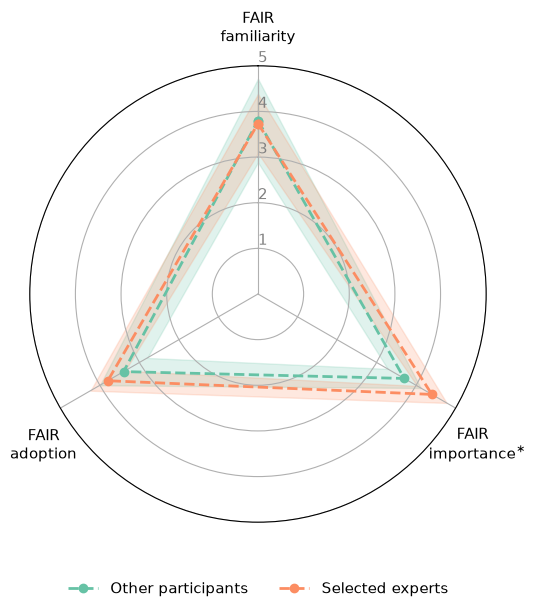

In [20]:
qs = ['How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)',
      'How important is it to follow FAIR principles? 1 (Not important) – 5 (Extremely important)',              
      'To what extent do you apply the FAIR principles in your research or software development work? 1 (Never apply) – 5 (Always apply)',
]
df = cleaned_data.copy()
qq = q(qs, df)
df1 = df[df['Selected_expert'] == 1]
df1 = df1[qq]
df1['Category'] = 'Selected experts'
print(df1.mean(numeric_only=True))
df2 = df[df['Selected_expert'] == 0]
df2 = df2[qq]
df2 = df2[~df2.index.isin(df1.index)]
df2['Category'] = 'Other participants'
print(len(df1), len(df2))
df = pd.concat([df1, df2], ignore_index=True)
radar_chart_ci(qs+['Category'], qq+['Category'], df, labels={
    qs[0]: 'FAIR\nfamiliarity\n\n',
    qs[1]: '\n\n\nFAIR\n  importance$^{\\ast}$',
    qs[2]: '\n\n\nFAIR\nadoption',
},
file_name='fig05a', left=1, ci=0.95, ci_method="sem", 
loc="upper center", 
linestyle='--', figsize=(5.5, 6.5))
get_stars(0.0221)

In [21]:
d = df.groupby('Category').mean(numeric_only=True).map(lambda x: f"{x:.2f}").T
d.to_csv(os.path.join(figures_dir, "fig05b.csv"), index=True)
d

Category,Other participants,Selected experts
"How familiar are you with the FAIR principles (Findable, Accessible, Interoperable, Reusable, see the introductory paper)? 1 (Not familiar) – 5 (Very familiar)",3.77,3.96
How important is it to follow FAIR principles? 1 (Not important) – 5 (Extremely important),3.82,4.40
To what extent do you apply the FAIR principles in your research or software development work? 1 (Never apply) – 5 (Always apply),3.42,3.81


<Axes: xlabel='Rating (1-5)'>

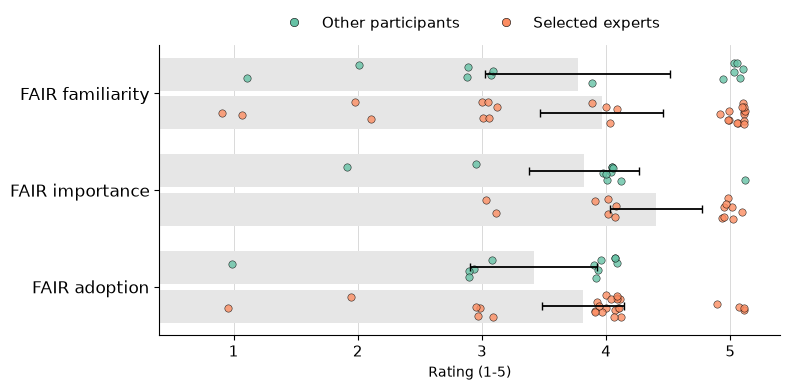

In [22]:
draw_likert_dist(df, qq, group='Category',
                  labels=dict(zip(qq, ['FAIR familiarity', 'FAIR importance', 'FAIR adoption'])),
                  file_name='fig05a_bar', figsize=(8, 4), xlabel='Rating (1-5)')

20
Friedman chi-square: 8.496644295301992
p-value: 0.07498900973491922
Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S1 Energy efficiency attributes]: p=0.009
Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S2 Sustainability benchmarks]: p=0.021
Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S3 Alignment with sustainability frameworks]: p=0.028
Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S4 Carbon transparency and accountability]: p=0.014
Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S5 Life cycle sustainability]: p=0.151


<Axes: >

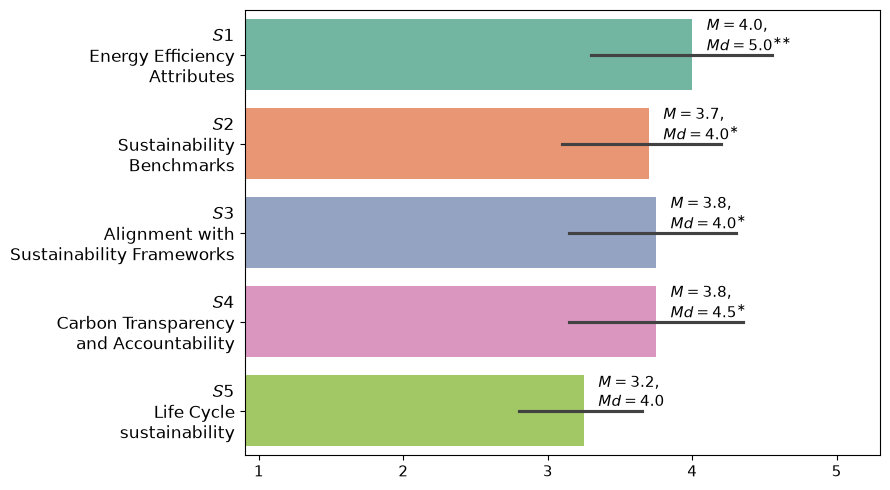

In [23]:
qs = ['Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S1 Energy efficiency attributes]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S2 Sustainability benchmarks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S3 Alignment with sustainability frameworks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S4 Carbon transparency and accountability]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S5 Life cycle sustainability]']
df = cleaned_data.copy()
qq = q(qs, df)
df = df[df['Selected_expert'] == 1]
df = df[qq].astype(float).dropna()
print(len(df))
stat, p = friedmanchisquare(*[df[col].values for col in df.columns])
print("Friedman chi-square:", stat) # Friedman → “Are categories different?”
print("p-value:", p) # p < 0.05 → at least one category differs in importance

pvals = []
for col in df.columns:
    _, p = wilcoxon(df[col] - 3, alternative='greater') # p < 0.05 → ratings are significantly different from 3
    print(f"{col}: p={p:.3f}")
    pvals.append(f"$M={np.mean(df[col]):.1f}$,\n$Md={np.median(df[col]):.1f}^{{{get_stars(p)}}}$".replace('*', r'{\ast}'))

draw_hbar(qs, qq, df, labels={
    qs[0]: '$S1$\nEnergy Efficiency\nAttributes',
    qs[1]: '$S2$\nSustainability\nBenchmarks',
    qs[2]: '$S3$\nAlignment with\nSustainability Frameworks',
    qs[3]: '$S4$\nCarbon Transparency\nand Accountability', 
    qs[4]: '$S5$\nLife Cycle\nsustainability',  
}, file_name='fig06', annot=pvals, figsize=(9, 5))



<Axes: xlabel='Rating (1-5)'>

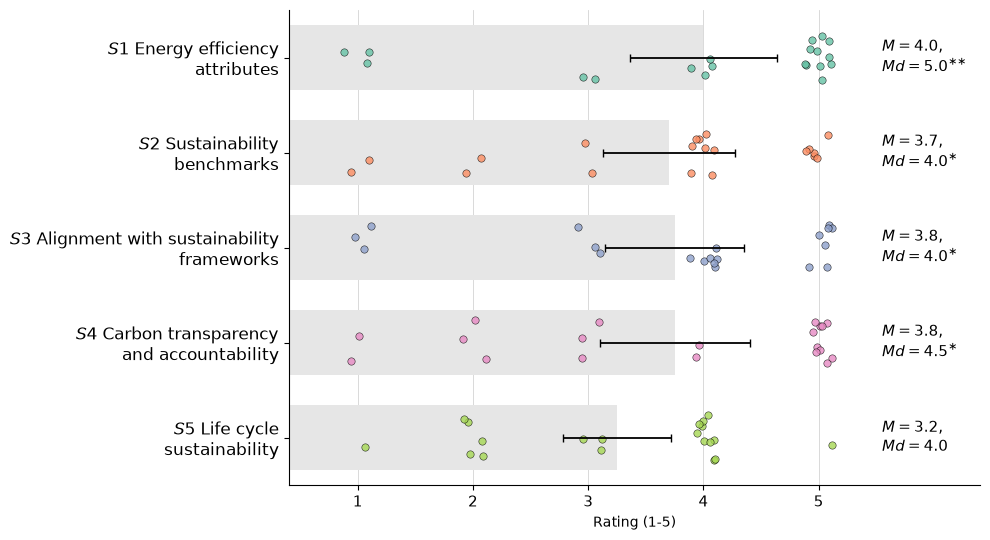

In [24]:
draw_likert_dist(df, qq, labels=dict(zip(qq, [
    '$S1$ Energy efficiency\nattributes', '$S2$ Sustainability\nbenchmarks',
    '$S3$ Alignment with sustainability\nframeworks', '$S4$ Carbon transparency\nand accountability',
    '$S5$ Life cycle\nsustainability'])),
    annot=pvals, file_name='fig06_bar', figsize=(10, 5.5), xlabel='Rating (1-5)')

20
To what extent do you agree that validated sustainability benchmarks/tools are necessary? 1 (Strongly disagree) – 5 (Strongly agree): p=0.001
How likely would you be to adopt sustainability benchmarks if clear community standards existed? 1 (Not likely) – 5 (Very likely): p=0.001
How valuable would standardize sustainability certifications (similar to FAIR badges) be for software and datasets? 1 (Not valuable) – 5 (Extremely valuable): p=0.001
How important is transparency in sustainability reporting for research artifacts? 1 (Not important) – 5 (Extremely important): p=0.000
['$M=4.2$,\n$Md=5.0^{{\\ast}{\\ast}}$', '$M=4.2$,\n$Md=5.0^{{\\ast}{\\ast}}$', '$M=4.0$,\n$Md=4.0^{{\\ast}{\\ast}{\\ast}}$', '$M=4.5$,\n$Md=5.0^{{\\ast}{\\ast}{\\ast}}$']


<Axes: >

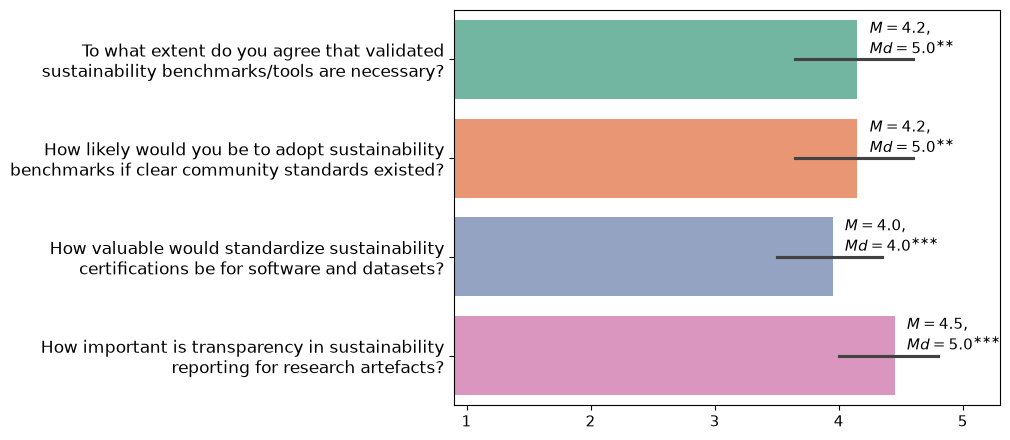

In [25]:
qs = ['To what extent do you agree that validated sustainability benchmarks/tools are necessary? 1 (Strongly disagree) – 5 (Strongly agree)',
'How likely would you be to adopt sustainability benchmarks if clear community standards existed? 1 (Not likely) – 5 (Very likely)',
'How valuable would standardize sustainability certifications (similar to FAIR badges) be for software and datasets? 1 (Not valuable) – 5 (Extremely valuable)',
'How important is transparency in sustainability reporting for research artifacts? 1 (Not important) – 5 (Extremely important)'
]
df = cleaned_data.copy()
qq = q(qs, df)
df = df[df['Selected_expert'] == 1]
df = df[qq].astype(float).dropna()
print(len(df))
vals = []
for col in df.columns:
    _, p = wilcoxon(df[col] - 3, alternative='greater')
    print(f"{col}: p={p:.3f}")
    vals.append(f"$M={np.mean(df[col]):.1f}$,\n$Md={np.median(df[col]):.1f}^{{{get_stars(p)}}}$".replace('*', r'{\ast}'))

print(vals)
draw_hbar(qs, qq, df, labels={
    qs[0]: 'To what extent do you agree that validated\nsustainability benchmarks/tools are necessary?',
    qs[1]: 'How likely would you be to adopt sustainability\nbenchmarks if clear community standards existed?', 
    qs[2]: 'How valuable would standardize sustainability\ncertifications be for software and datasets?',
    qs[3]: 'How important is transparency in sustainability\nreporting for research artefacts?', 
}, file_name='fig07a', annot=vals, figsize=(10.2, 4.5))

<Axes: xlabel='Rating (1-5)'>

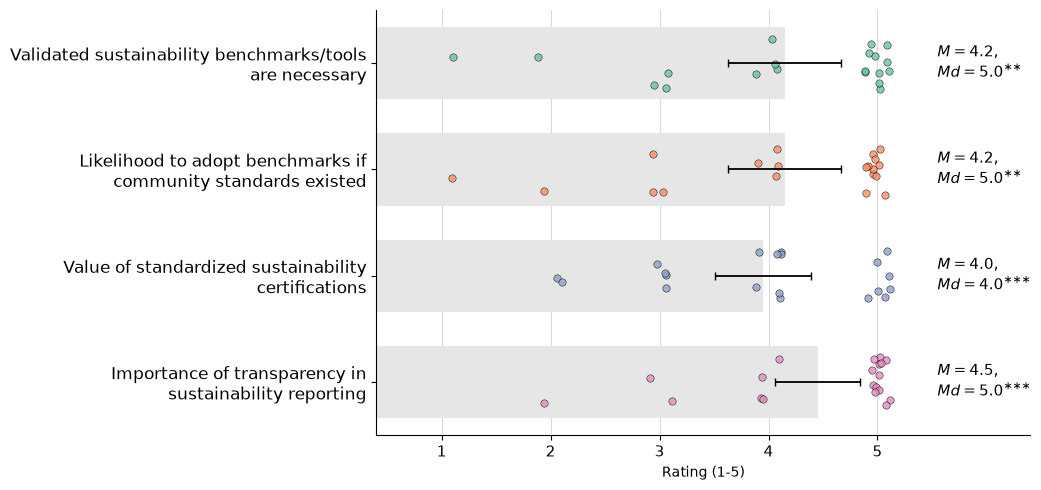

In [26]:
draw_likert_dist(df, qq, labels=dict(zip(qq, [
    'Validated sustainability benchmarks/tools\nare necessary',
    'Likelihood to adopt benchmarks if\ncommunity standards existed',
    'Value of standardized sustainability\ncertifications',
    'Importance of transparency in\nsustainability reporting'])),
    annot=vals, file_name='fig07a_bar', figsize=(10.5, 5), xlabel='Rating (1-5)')

21


['Would lifecycle sustainability statements improve your trust in published datasets/software? [Yes]',
 'Would lifecycle sustainability statements improve your trust in published datasets/software? [No]',
 'Would lifecycle sustainability statements improve your trust in published datasets/software? [Unsure]']

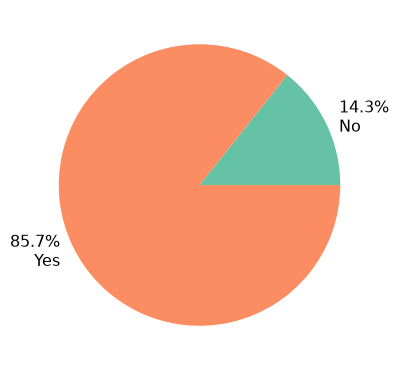

In [27]:
qs = ['Would lifecycle sustainability statements improve your trust in published datasets/software? [Yes]',
      'Would lifecycle sustainability statements improve your trust in published datasets/software? [No]',
      'Would lifecycle sustainability statements improve your trust in published datasets/software? [Unsure]']
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'Yes': 1,
    'No': 0,
    np.nan: 0,
    None: 0,
})
df[qq[0]] = df[qq[0]].map({
    1: 'Yes',
    0: np.nan,
})
df[qq[1]] = df[qq[1]].map({
    1: 'No',
    0: np.nan,
})
df[qq[2]] = df[qq[2]].map({
    1: 'Unsure',
    0: np.nan,
})
df['category1'] = df[qq[0]].combine_first(df[qq[1]]).combine_first(df[qq[2]])
df = df[['category1']]
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig07b', width=4, height=4,
         labeldistance=1.1, )
qq


array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

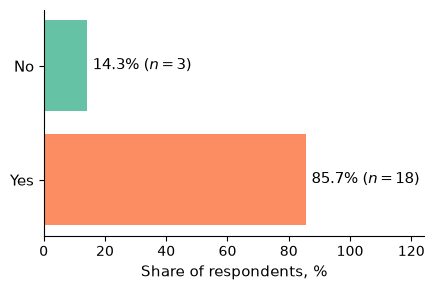

In [28]:
draw_cat_bar(df, file_name='fig07b_bar')

21


['Would you support mandatory disclosure of methods/tools used for energy measurement? [Yes]',
 'Would you support mandatory disclosure of methods/tools used for energy measurement? [No]',
 'Would you support mandatory disclosure of methods/tools used for energy measurement? [Unsure]']

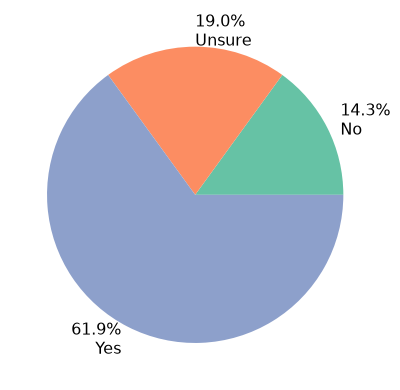

In [29]:
qs = ['Would you support mandatory disclosure of methods/tools used for energy measurement? [Yes]', 
      'Would you support mandatory disclosure of methods/tools used for energy measurement? [No]', 
      'Would you support mandatory disclosure of methods/tools used for energy measurement? [Unsure]']
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna().replace({
    'Yes': 1,
    'No': 0,
    np.nan: 0,
    None: 0,
})
df[qq[0]] = df[qq[0]].map({
    1: 'Yes',
    0: np.nan,
})
df[qq[1]] = df[qq[1]].map({
    1: 'No',
    0: np.nan,
})
df[qq[2]] = df[qq[2]].map({
    1: 'Unsure',
    0: np.nan,
})
df['category2'] = df[qq[0]].combine_first(df[qq[1]]).combine_first(df[qq[2]])
df = df[['category2']]
print(len(df))
draw_pie(df, nrows=1, ncols=1, file_name='fig07c', width=4, height=4,
         labeldistance=1.1, )
qq


array([[<Axes: xlabel='Share of respondents, %'>]], dtype=object)

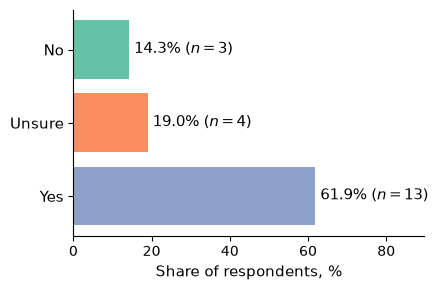

In [30]:
draw_cat_bar(df, file_name='fig07c_bar')

23
Do you consider it practical to include energy efficiency attributes in research artifact metadata? 1 (Strongly impractical) – 5 (Highly practical): p=0.124
How feasible is it to report hardware/software/network context or specifications when publishing research? 1 (Not feasible) – 5 (Very feasible): p=0.000


<Axes: >

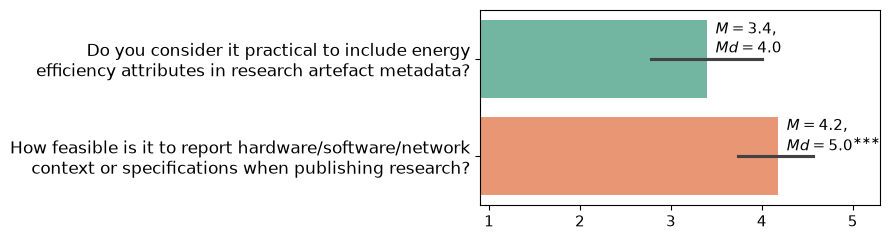

In [31]:
qs = ['Do you consider it practical to include energy efficiency attributes in research artifact metadata? 1 (Strongly impractical) – 5 (Highly practical)',
      'How feasible is it to report hardware/software/network context or specifications when publishing research? 1 (Not feasible) – 5 (Very feasible)']
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].dropna()
print(len(df))

vals = []
for col in df.columns:
    _, p = wilcoxon(df[col] - 3, alternative='greater')
    print(f"{col}: p={p:.3f}")
    # pvals.append(r"$\text{mean}=" + f"{np.mean(df[col]):.1f}, p={p:.3f}$")
    vals.append(f"$M={np.mean(df[col]):.1f}$,\n$Md={np.median(df[col]):.1f}^{{{get_stars(p)}}}$".replace('*', r'{\ast}'))

draw_hbar(qs, qq, df, labels={
    qq[0]:'Do you consider it practical to include energy\nefficiency attributes in research artefact metadata?',
    qq[1]:'How feasible is it to report hardware/software/network\ncontext or specifications when publishing research?', 
}, file_name='fig08a', figsize=(9, 2.5), annot=vals)

<Axes: xlabel='Rating (1-5)'>

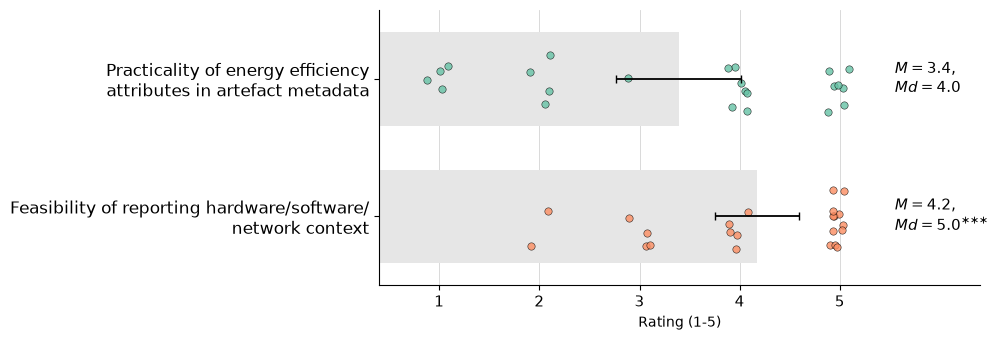

In [32]:
draw_likert_dist(df, qq, labels=dict(zip(qq, [
    'Practicality of energy efficiency\nattributes in artefact metadata',
    'Feasibility of reporting hardware/software/\nnetwork context'])),
    annot=vals, file_name='fig08a_bar', figsize=(10, 3.5), xlabel='Rating (1-5)')

27
                          0
0              CPU/GPU type
1              CPU/GPU type
2              CPU/GPU type
3              CPU/GPU type
5              CPU/GPU type
..                      ...
13  System logs/Energy logs
7              None of them
8              None of them
13                    Other
25                    Other

[63 rows x 1 columns]


['Which hardware/software details do you usually report in any of your research (if any)? [CPU / GPU type]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Memory]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Software framework]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Operating System / Environment]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Cloud provider / Region]',
 'Which hardware/software details do you usually report in any of your research (if any)? [System logs / Energy logs]',
 'Which hardware/software details do you usually report in any of your research (if any)? [None of them]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Other]']

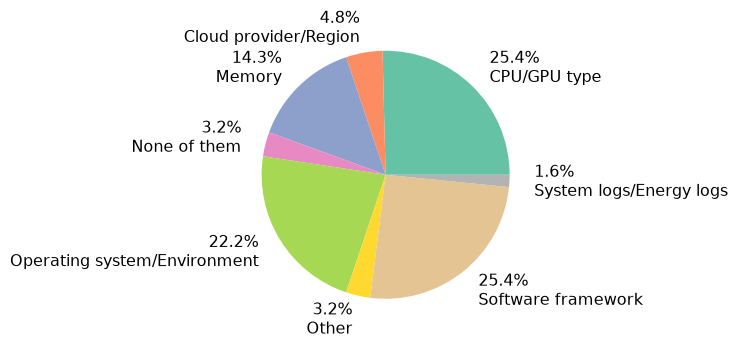

In [33]:
qs = ['Which hardware/software details do you usually report in any of your research (if any)? [CPU / GPU type]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Memory]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Software framework]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Operating System / Environment]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Cloud provider / Region]',
 'Which hardware/software details do you usually report in any of your research (if any)? [System logs / Energy logs]',
 'Which hardware/software details do you usually report in any of your research (if any)? [None of them]',
 'Which hardware/software details do you usually report in any of your research (if any)? [Other]']
df = cleaned_data.copy()
df = df[df['Selected_expert'] == 1]
qq = q(qs, df)
df = df[qq].replace({
    'Yes': 1,
    'No': 0,
    np.nan: 0,
    None: 0,
})
print(len(df))
df[qq[0]] = df[qq[0]].map({
    1: 'CPU/GPU type',
    0: np.nan,
})
df[qq[1]] = df[qq[1]].map({
    1: 'Memory',
    0: np.nan,
})
df[qq[2]] = df[qq[2]].map({
    1: 'Software framework',
    0: np.nan,
})
df[qq[3]] = df[qq[3]].map({
    1: 'Operating system/Environment',
    0: np.nan,
})
df[qq[4]] = df[qq[4]].map({
    1: 'Cloud provider/Region',
    0: np.nan,
})
df[qq[5]] = df[qq[5]].map({
    1: 'System logs/Energy logs',
    0: np.nan,
})
df[qq[6]] = df[qq[6]].map({
    1: 'None of them',
    0: np.nan,
})
df[qq[7]] = df[qq[7]].apply(lambda x: 'Other' if x != 0 else np.nan)
df = pd.DataFrame(pd.concat([df[i] for i in df.columns], axis=0).dropna())
print(df)
draw_pie(df, nrows=1, ncols=1, file_name='fig08b',
         labeldistance=1.2, width=4, height=4.5)
qq

array([[<Axes: xlabel='Share of all answers, %'>]], dtype=object)

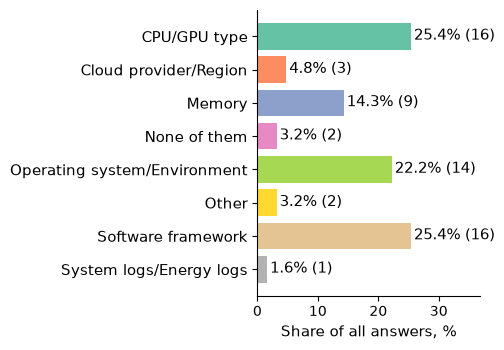

In [34]:
draw_cat_bar(df, file_name='fig08b_bar', height=3.6, width=5, xlabel='Share of all answers, %', don=False)

### Agreement between experts on the sustainability principles (S1–S5)
Are there a few experts who rate all principles as unimportant, or are opinions differentiated across principles?

n = 20
Spearman rho between principles: mean=0.53, min=0.14, max=0.74
Cronbach alpha = 0.89
respondents rating ALL principles <= 2: 1
respondents rating ALL principles <= 3: 3
respondents with mean <= 2.5: 3
respondents giving identical rating to all five: 1
respondents with a spread (max-min) >= 2: 13 (65%)
mean within-person SD = 0.80


,S1,S2,S3,S4,S5
S1,1.00,0.74,0.50,0.52,0.49
S2,0.74,1.00,0.61,0.72,0.41
S3,0.50,0.61,1.00,0.72,0.44
S4,0.52,0.72,0.72,1.00,0.14
S5,0.49,0.41,0.44,0.14,1.00


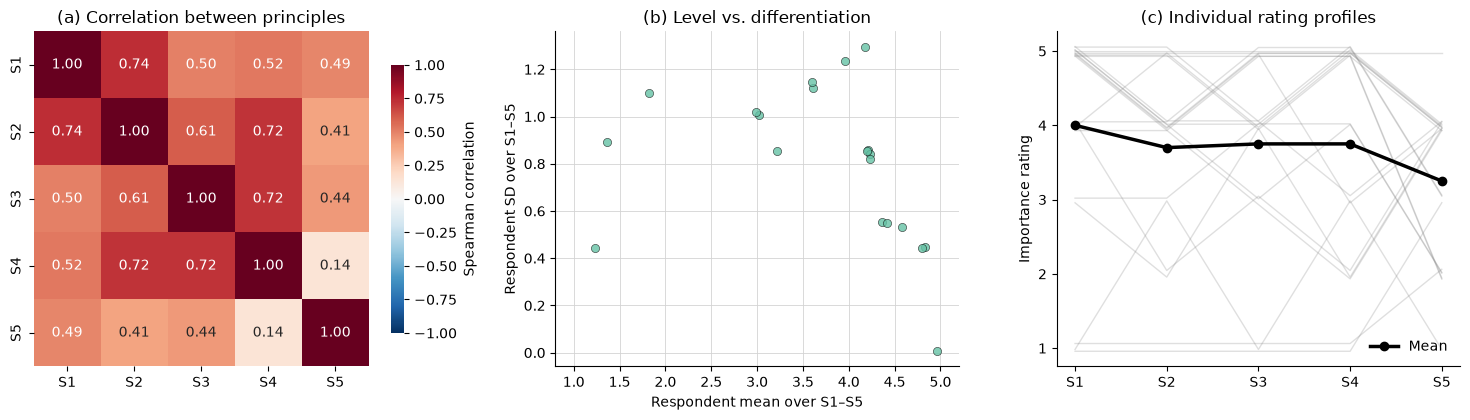

In [35]:
# Do a few experts rate all FAIR+S (S1-S5) principles as unimportant, or are opinions differentiated?
qs = ['Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S1 Energy efficiency attributes]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S2 Sustainability benchmarks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S3 Alignment with sustainability frameworks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S4 Carbon transparency and accountability]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S5 Life cycle sustainability]']
short = ['S1', 'S2', 'S3', 'S4', 'S5']
df = cleaned_data.copy()
qq = q(qs, df)
df = df[df['Selected_expert'] == 1][qq].astype(float).dropna()
df.columns = short
n = len(df)
print(f"n = {n}")

# 1) Inter-item correlations (Spearman, ordinal data)
rho = df.corr(method='spearman')
pv = pd.DataFrame({a: {b: stats.spearmanr(df[a], df[b])[1] for b in short} for a in short})
off = rho.values[np.triu_indices(5, 1)]
print(f"Spearman rho between principles: mean={off.mean():.2f}, min={off.min():.2f}, max={off.max():.2f}")
k = 5
alpha = k / (k - 1) * (1 - df.var().sum() / df.sum(axis=1).var())
print(f"Cronbach alpha = {alpha:.2f}")

# 2) Per-respondent patterns
mean_r, sd_r, rng_r = df.mean(axis=1), df.std(axis=1), df.max(axis=1) - df.min(axis=1)
print(f"respondents rating ALL principles <= 2: {(df.max(axis=1) <= 2).sum()}")
print(f"respondents rating ALL principles <= 3: {(df.max(axis=1) <= 3).sum()}")
print(f"respondents with mean <= 2.5: {(mean_r <= 2.5).sum()}")
print(f"respondents giving identical rating to all five: {(rng_r == 0).sum()}")
print(f"respondents with a spread (max-min) >= 2: {(rng_r >= 2).sum()} ({(rng_r >= 2).mean()*100:.0f}%)")
print(f"mean within-person SD = {sd_r.mean():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1.1, 1, 1]})
# (a) correlation heatmap
ax = axes[0]
sns.heatmap(rho, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': "Spearman correlation", 'shrink': 0.8})
ax.set_title('(a) Correlation between principles')
# (b) mean vs. spread per respondent
ax = axes[1]
rr = np.random.default_rng(0)
ax.scatter(mean_r + rr.uniform(-0.04, 0.04, n), sd_r + rr.uniform(-0.02, 0.02, n), s=35,
           color=sns.color_palette('Set2')[0], edgecolor='black', linewidth=0.4, alpha=0.8)
ax.set_xlim(0.8, 5.2)
ax.set_xlabel('Respondent mean over S1–S5')
ax.set_ylabel('Respondent SD over S1–S5')
ax.set_title('(b) Level vs. differentiation')
ax.grid(color='lightgrey', lw=0.6); ax.set_axisbelow(True); sns.despine(ax=ax)
# (c) individual profiles
ax = axes[2]
for _, row in df.iterrows():
    ax.plot(range(5), row.values + rr.uniform(-0.08, 0.08), color='grey', alpha=0.25, lw=1)
ax.plot(range(5), df.mean().values, 'o-', color='black', lw=2.5, label='Mean')
ax.set_xticks(range(5), short)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylabel('Importance rating')
ax.set_title('(c) Individual rating profiles')
ax.legend(frameon=False); sns.despine(ax=ax)
fig.tight_layout()
#fig.savefig(os.path.join(figures_dir, 'fig09_correlation.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
rho.round(2)

n = 20
Spearman rho between principles: mean=0.53, min=0.14, max=0.74
Cronbach alpha = 0.89


,S1,S2,S3,S4,S5
S1,1.00,0.74,0.50,0.52,0.49
S2,0.74,1.00,0.61,0.72,0.41
S3,0.50,0.61,1.00,0.72,0.44
S4,0.52,0.72,0.72,1.00,0.14
S5,0.49,0.41,0.44,0.14,1.00


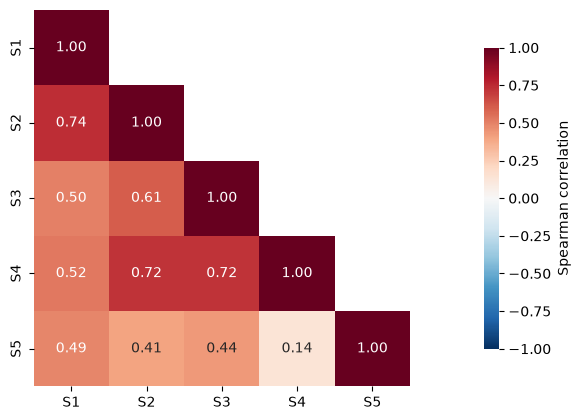

In [36]:
# Do a few experts rate all FAIR+S (S1-S5) principles as unimportant, or are opinions differentiated?
qs = ['Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S1 Energy efficiency attributes]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S2 Sustainability benchmarks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S3 Alignment with sustainability frameworks]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S4 Carbon transparency and accountability]',
      'Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S5 Life cycle sustainability]']
short = ['S1', 'S2', 'S3', 'S4', 'S5']
df = cleaned_data.copy()
qq = q(qs, df)
df = df[df['Selected_expert'] == 1][qq].astype(float).dropna()
df.columns = short
n = len(df)
print(f"n = {n}")

# 1) Inter-item correlations (Spearman, ordinal data)
rho = df.corr(method='spearman')
pv = pd.DataFrame({a: {b: stats.spearmanr(df[a], df[b])[1] for b in short} for a in short})
off = rho.values[np.triu_indices(5, 1)]
print(f"Spearman rho between principles: mean={off.mean():.2f}, min={off.min():.2f}, max={off.max():.2f}")
k = 5
alpha = k / (k - 1) * (1 - df.var().sum() / df.sum(axis=1).var())
print(f"Cronbach alpha = {alpha:.2f}")

fig, ax = plt.subplots(figsize=(15, 4.3))
# (a) correlation heatmap
mask = np.triu(np.ones_like(rho, dtype=bool), k=1)
sns.heatmap(rho, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': "Spearman correlation", 'shrink': 0.8})
#ax.set_title('(a) Correlation between principles')
fig.tight_layout()
fig.savefig(os.path.join(figures_dir, 'fig09_correlation.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
rho.round(2)

## Revision additions
The cells below were added in response to the second review round. Everything above is unchanged.
They (i) report multiple-choice items as the share of **respondents** instead of the share of all selections (Fig. 2, Fig. 9b),
(ii) report Cronbach's alpha in raw and standardised form with a bootstrap CI (Fig. 7), and (iii) describe the S5 distribution.

In [25]:
def draw_multi_bar(counts, n_resp, file_name=None, width=5, height=3.2, xlabel=None):
    """Multiple-choice item: bars = share of respondents choosing the option (can sum to >100%)."""
    plt.close()
    counts = counts.sort_values(ascending=False)
    pct = counts / n_resp * 100
    fig, ax = plt.subplots(figsize=(width, height))
    ax.barh(list(counts.index), pct.values, color=sns.color_palette('Set2')[:len(counts)])
    ax.invert_yaxis()
    for y, (p, n) in enumerate(zip(pct.values, counts.values)):
        ax.text(p + pct.max() * 0.02, y, f"{p:.1f}% ($n={n}$)", va='center', fontsize=10.5)
    ax.set_xlim(0, pct.max() * 1.5)
    ax.set_xlabel(xlabel or f'Share of respondents, % ($n={n_resp}$; multiple answers allowed)', size=11)
    ax.tick_params(axis='y', labelsize=11)
    sns.despine(ax=ax)
    fig.tight_layout()
    if file_name is not None:
        fig.savefig(os.path.join(figures_dir, f'{file_name}.pdf'), dpi=1200, bbox_inches='tight', format='pdf')
    return ax

### Fig. 2 (Q1) - primary field of research: share of respondents (multiple choice)

respondents: 27 | total selections: 37
{'Computer Science': 66.7, 'Engineering': 40.7, 'Social Sciences': 18.5, 'Life Sciences': 3.7, 'Other': 7.4}


<Axes: xlabel='Share of respondents, %'>

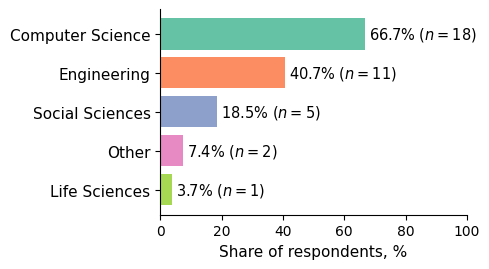

In [ ]:
pref = 'What is your primary field of research or development? ['
names = {'Computer Science related': 'Computer Science', 'Engineering related': 'Engineering',
         'Social Sciences related': 'Social Sciences', 'Life Sciences related': 'Life Sciences', 'Other': 'Other'}
d = cleaned_data[cleaned_data['Selected_expert'] == 1]
sel = {}
for k, v in names.items():
    col = d[pref + k + ']']
    sel[v] = col.notna().sum() if k == 'Other' else (col == 'Yes').sum()
sel = pd.Series(sel)
n_resp = len(d)                      # all 27 experts answered Q1
print('respondents:', n_resp, '| total selections:', sel.sum())
print((sel / n_resp * 100).round(1).to_dict())
draw_multi_bar(sel, n_resp, file_name='fig02_resp', width=5, height=2.8, xlabel='Share of respondents, %')

### Fig. 9b (Q15) - reported hardware/software details: share of respondents (multiple choice)

experts: 27 | answered Q15: 24
total selections: 63
{'CPU/GPU type': 66.7, 'Memory': 37.5, 'Software framework': 66.7, 'Operating system/Environment': 58.3, 'Cloud provider/Region': 12.5, 'System logs/Energy logs': 4.2, 'None of them': 8.3, 'Other': 8.3}


<Axes: xlabel='Share of respondents, %'>

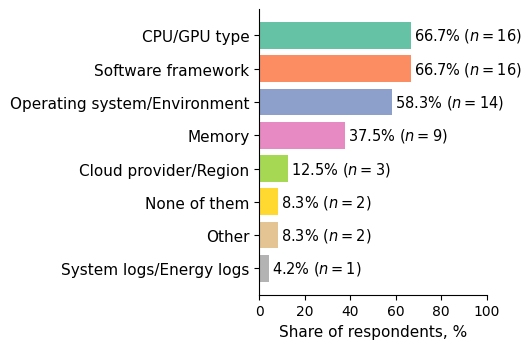

In [29]:
pref = 'Which hardware/software details do you usually report in any of your research (if any)? ['
names = {'CPU / GPU type': 'CPU/GPU type', 'Memory': 'Memory', 'Software framework': 'Software framework',
         'Operating System / Environment': 'Operating system/Environment', 'Cloud provider / Region': 'Cloud provider/Region',
         'System logs / Energy logs': 'System logs/Energy logs', 'None of them': 'None of them', 'Other': 'Other'}
d = cleaned_data[cleaned_data['Selected_expert'] == 1]
cols = [pref + k + ']' for k in names]
answered = d[cols].notna().any(axis=1)       # respondents who answered Q15 at all
print('experts:', len(d), '| answered Q15:', answered.sum())
sel = {}
for k, v in names.items():
    col = d[pref + k + ']']
    sel[v] = col.notna().sum() if k == 'Other' else (col == 'Yes').sum()
sel = pd.Series(sel)
print('total selections:', sel.sum())
print((sel / answered.sum() * 100).round(1).to_dict())
draw_multi_bar(sel, int(answered.sum()), file_name='fig08b_resp', width=5.2, height=3.6, xlabel='Share of respondents, %')

### Fig. 7 - Cronbach's alpha: raw vs. standardised, bootstrap CI, alpha without S5

In [31]:
qs = ['Which FAIR+S principles (S1–S5) do you find most critical for adoption? 1 (Not important) – 5 (Very important) [S%d %s]' % (i, t)
      for i, t in [(1, 'Energy efficiency attributes'), (2, 'Sustainability benchmarks'),
                   (3, 'Alignment with sustainability frameworks'), (4, 'Carbon transparency and accountability'),
                   (5, 'Life cycle sustainability')]]
d = cleaned_data[cleaned_data['Selected_expert'] == 1]
X = d[qs].astype(float).dropna(); X.columns = ['S1', 'S2', 'S3', 'S4', 'S5']
print('n =', len(X))


def alpha_raw(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var().sum() / x.sum(axis=1).var())


def alpha_std(x, method='pearson'):
    k = x.shape[1]
    r = x.corr(method=method).values[np.triu_indices(k, 1)].mean()
    return k * r / (1 + (k - 1) * r)


res = {'raw alpha (covariance-based; reported value)': alpha_raw(X),
       'standardised alpha (mean Pearson r)': alpha_std(X, 'pearson'),
       'standardised alpha (mean Spearman rho, as in the heatmap)': alpha_std(X, 'spearman'),
       'raw alpha S1-S4 (without S5)': alpha_raw(X[['S1', 'S2', 'S3', 'S4']])}
for k_, v_ in res.items():
    print(f"{k_}: {v_:.2f}")
rng = np.random.default_rng(0)
boot = [alpha_raw(X.sample(len(X), replace=True, random_state=int(s))) for s in rng.integers(0, 10**6, 5000)]
boot = np.array([b for b in boot if np.isfinite(b)])
print("raw alpha, 95%% bootstrap CI (percentile): [%.2f, %.2f]" % tuple(np.percentile(boot, [2.5, 97.5])))
print("alpha if item deleted:", {c: round(alpha_raw(X.drop(columns=c)), 2) for c in X.columns})

n = 20
raw alpha (covariance-based; reported value): 0.89
standardised alpha (mean Pearson r): 0.88
standardised alpha (mean Spearman rho, as in the heatmap): 0.85
raw alpha S1-S4 (without S5): 0.92
raw alpha, 95% bootstrap CI (percentile): [0.68, 0.94]
alpha if item deleted: {'S1': 0.83, 'S2': 0.84, 'S3': 0.83, 'S4': 0.87, 'S5': 0.92}


### S5 - distribution of ratings (replaces the description 'on average neutral')

In [32]:
s5 = X['S5']
dist = s5.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
print(dist.to_dict(), f"| M = {s5.mean():.2f}, Md = {s5.median():.1f}, SD = {s5.std():.2f}, range {s5.min():.0f}-{s5.max():.0f}")
for c in X.columns:
    print(c, 'rated 4-5: %d/%d = %.0f%%' % ((X[c] >= 4).sum(), len(X), (X[c] >= 4).mean() * 100),
          '| rated 3: %d = %.0f%%' % ((X[c] == 3).sum(), (X[c] == 3).mean() * 100),
          '| rated 1-2: %d = %.0f%%' % ((X[c] <= 2).sum(), (X[c] <= 2).mean() * 100),
          '| Wilcoxon vs 3 (one-sided, as in Fig. 6): p = %.3f' % wilcoxon(X[c] - 3, alternative='greater').pvalue)

{1: 1, 2: 5, 3: 3, 4: 10, 5: 1} | M = 3.25, Md = 4.0, SD = 1.07, range 1-5
S1 rated 4-5: 15/20 = 75% | rated 3: 2 = 10% | rated 1-2: 3 = 15% | Wilcoxon vs 3 (one-sided, as in Fig. 6): p = 0.009
S2 rated 4-5: 14/20 = 70% | rated 3: 2 = 10% | rated 1-2: 4 = 20% | Wilcoxon vs 3 (one-sided, as in Fig. 6): p = 0.021
S3 rated 4-5: 14/20 = 70% | rated 3: 3 = 15% | rated 1-2: 3 = 15% | Wilcoxon vs 3 (one-sided, as in Fig. 6): p = 0.028
S4 rated 4-5: 12/20 = 60% | rated 3: 3 = 15% | rated 1-2: 5 = 25% | Wilcoxon vs 3 (one-sided, as in Fig. 6): p = 0.014
S5 rated 4-5: 11/20 = 55% | rated 3: 3 = 15% | rated 1-2: 6 = 30% | Wilcoxon vs 3 (one-sided, as in Fig. 6): p = 0.151
